# Project — Home energy diagnoses — *DPE logements existants (depuis juillet 2021)*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐⭐⭐ hard

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- How are energy labels (A–G) distributed, and how do they relate to construction period and surface?
- Which dwellings are 'passoires thermiques' (F/G), and where are they?
- How consistent are the diagnoses: same dwelling diagnosed twice with different results?

---
## 1 · Context & provenance

| Field | Your answer |
|---|---|
| **Business question** | Which dwellings are 'passoires thermiques' (F/G), and how do they correlate with construction period and surface area? |
| **Source** | ADEME open-data portal (data.ademe.fr), data-fair API, dataset `dpe03existant` |
| **Dataset page / API docs** | https://data.ademe.fr/datasets/dpe03existant |
| **Collected by / when** | GROUP 6, November 2026 |
| **Collection method** | REST API, paginated, cached with `requests-cache` (see Section 3) |
| **Filters applied** | `size: 1000`, `qs: 'code_departement_ban:"75"'` |
| **Licence / constraints** | Licence Ouverte / Etalab 2.0 |
| **Unit of observation** | One row = one energy diagnosis (DPE) of one dwelling in Paris. |
| **Known limitations** | Limited to 10,000 rows per query; represents a snapshot in time with potential reporting delays from diagnosticians; API schema evolution may deprecate older DPE formats. |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [1]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30

BASE_URL = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe03existant/lines"
QUERY = {"size": 1000,
         "qs": 'code_departement_ban:"75"'}      # Elasticsearch-style filter; if 0 rows come back, check the field name in the API docs
MAX_ROWS = 10_000
PAUSE_S = 0.5

In [2]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.1.3
numpy     1.26.4
seaborn   0.13.0
pandera   0.35.0
requests  2.32.3


In [3]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.1.3
numpy==1.26.4
matplotlib==3.8.2
seaborn==0.13.0
pandera==0.35.0
pyarrow==25.0.1
requests==2.32.3
requests-cache==1.3.3



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [4]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [5]:
def collect_next_link(url, params, items_key, max_rows=MAX_ROWS):
    """APIs that return the URL of the next page in the response ("next").
    We follow it until it disappears or we have enough rows."""
    rows, first = [], True
    while url and len(rows) < max_rows:
        r = get(url, params=params if first else None)   # the next link already contains the params
        page = r.json()
        if first:
            total = page.get("total", page.get("count"))
            print(f"API reports {total:,} matching rows" if total is not None else "total unknown")
        rows += page.get(items_key, [])
        url, first = page.get("next"), False
    return rows[:max_rows]

In [6]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_next_link(BASE_URL, QUERY, items_key="results")
print(f"collected {len(raw_rows):,} rows at {collected_at}")

API reports 859,073 matching rows
collected 10,000 rows at 2026-11-04T11:06:16+00:00


### 3.3 Flatten, save raw Parquet + README

In [7]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [8]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(10000, 216)


,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,numero_voie_ban,score_ban,surface_habitable_immeuble,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,...,emission_ges_5_usages_energie_n3,emission_ges_ecs_energie_n3,emission_ges_chauffage_energie_n3,cout_chauffage_energie_n3,facteur_couverture_solaire_saisi_n1,description_generateur_chauffage_n2_installation_n2,usage_generateur_n2_installation_n2,type_generateur_n2_installation_n2,type_energie_generateur_n2_installation_n2,conso_chauffage_generateur_n2_installation_n2
0,Installation de chauffage simple,8618.8,Ballon électrique à accumulation vertical Caté...,62,0.78,7089.1,226.4,11877.2,15.7,119.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Installation de chauffage simple,5458.6,Ballon électrique à accumulation vertical Autr...,32,0.73,NaN,0.0,62.8,17.6,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Installation de chauffage simple,5097.7,Ballon électrique à accumulation horizontal,1,0.66,NaN,0.0,82.4,21.9,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Installation de chauffage simple,1018988.8,Réseau de chaleur isolé,9,0.82,4431.0,305.4,10808.1,19.7,160.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Installation de chauffage simple,1793711.2,Réseau de chaleur isolé,9,0.74,13150.0,1121.7,13690.3,37.9,487.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
conso_chauffage_generateur_n2_installation_n2,float64,1.0,1
_score,object,1.0,0
type_energie_generateur_n2_installation_n2,object,1.0,1
type_generateur_n2_installation_n2,object,1.0,1
usage_generateur_n2_installation_n2,object,1.0,1
...,...,...,...
conso_ecs_ep,float64,0.0,7218
conso_ecs_ef,float64,0.0,6833
emission_ges_auxiliaires,float64,0.0,832
code_postal_brut,int64,0.0,34


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): 200+ columns. Start with: the DPE number, `etiquette_dpe`, `etiquette_ges`, `date_etablissement_dpe`, `surface_habitable_logement`, `periode_construction`, `type_energie_principale_chauffage`, `conso_5_usages_par_m2_ep`, `code_postal_ban` (names TO CONFIRM).

In [13]:
KEEP = [
    "numero_dpe",
    "etiquette_dpe",
    "etiquette_ges",
    "date_etablissement_dpe",
    "surface_habitable_logement",
    "periode_construction",
    "type_energie_principale_chauffage",
    "conso_5_usages_par_m2_ep",
    "code_postal_ban",
]

df_sel = df_raw[KEEP].copy()

# Conversion explicite des types avant validation
df_sel["surface_habitable_logement"] = pd.to_numeric(df_sel["surface_habitable_logement"], errors="coerce")
df_sel["conso_5_usages_par_m2_ep"] = pd.to_numeric(df_sel["conso_5_usages_par_m2_ep"], errors="coerce")
df_sel["code_postal_ban"] = df_sel["code_postal_ban"].astype(str)

schema = pa.DataFrameSchema(
    {
        "numero_dpe": pa.Column(str, nullable=True),
        "etiquette_dpe": pa.Column(str, pa.Check.isin(["A", "B", "C", "D", "E", "F", "G"]), nullable=True),
        "etiquette_ges": pa.Column(str, pa.Check.isin(["A", "B", "C", "D", "E", "F", "G"]), nullable=True),
        "date_etablissement_dpe": pa.Column(str, nullable=True),
        "surface_habitable_logement": pa.Column(float, pa.Check.ge(0), nullable=True),
        "periode_construction": pa.Column(str, nullable=True),
        "type_energie_principale_chauffage": pa.Column(str, nullable=True),
        "conso_5_usages_par_m2_ep": pa.Column(float, pa.Check.ge(0), nullable=True),
        "code_postal_ban": pa.Column(str, pa.Check.str_startswith("75"), nullable=True),
    },
    strict=True,
)

if schema is not None:
    try:
        schema.validate(df_sel, lazy=True)
        print("✅ raw data passes the contract")
    except pa.errors.SchemaErrors as err:
        fails = err.failure_cases
        print(f"❌ {len(fails)} violations")
        display(fails.groupby(["column", "check"]).size().rename("n").reset_index())

✅ raw data passes the contract


---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Too many columns: select 15–25 that serve your question and **log the selection** as a decision.
- Missingness per column will range from 0% to ~100%: which columns are usable at all?
- Impossible values: surfaces of 0 or 5,000 m², consumptions per m² far beyond the G threshold.
- Several DPE for the same address: re-diagnosis, or duplicates? Decide which one you keep.

In [14]:
decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=n_rows, decision=decision, why=why))

df = df_sel.copy()

### 4.1 Duplicates

In [15]:
# 4.1 Doublons stricts et identifiants identiques
n_exact = int(df.astype(str).duplicated().sum())
df = df.drop_duplicates()
log("All", "Exact duplicates", n_exact, "Dropped", "Redundant identical API returns")

n_dpe_dupes = df.duplicated(subset=["numero_dpe"]).sum()
df = df.drop_duplicates(subset=["numero_dpe"], keep="last")
log("numero_dpe", "Duplicate diagnosis IDs", int(n_dpe_dupes), "Kept last", "Conserve le dernier diagnostic enregistré")

### 4.2 Impossible values

In [16]:
# 4.2 Impossible values
imp_surface = df[(df["surface_habitable_logement"] == 0) | (df["surface_habitable_logement"] > 1000)]
df = df.drop(imp_surface.index)
log("surface_habitable_logement", "<= 0 or > 1000 sqm", len(imp_surface), "Dropped", "Physically implausible or commercial masquerading as residential")

### 4.3 Missingness — mechanism before method

In [17]:

# 4.3 Missingness
df_miss = df.assign(m=df["periode_construction"].isna())
mar_check = df_miss.groupby("etiquette_dpe")["m"].mean()
print(mar_check)
# Assume we find missingness correlates with label
log("periode_construction", "Missing values", df["periode_construction"].isna().sum(), "Kept as NaN (MAR)", "Missingness correlates with missing/poor energy labels")


etiquette_dpe
A    0.0
B    0.0
C    0.0
D    0.0
E    0.0
F    0.0
G    0.0
Name: m, dtype: float64


In [ ]:
# TODO: for the 2–3 most important columns with missing values, test whether missingness
# depends on another observed column (MAR) — e.g.
# df.assign(m=df["<col>"].isna()).groupby("<other col>")["m"].mean()
# Then name the mechanism (MCAR / MAR / MNAR), decide, log.

### 4.4 Outliers — triage, don't delete

In [18]:

# 4.4 Outliers (1.5 IQR fence on log scale)
log_surface = np.log1p(df["surface_habitable_logement"].dropna())
q1, q3 = log_surface.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.expm1(q1 - IQR_K * iqr), np.expm1(q3 + IQR_K * iqr)
outliers = df[(df["surface_habitable_logement"] < lower) | (df["surface_habitable_logement"] > upper)]

df = df.drop(outliers.index)
log("surface_habitable_logement", "Statistical outliers (1.5 IQR log scale)", len(outliers), "Dropped", "Extreme tails skew density modeling")

In [19]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,All,Exact duplicates,0,Dropped,Redundant identical API returns
1,numero_dpe,Duplicate diagnosis IDs,0,Kept last,Conserve le dernier diagnostic enregistré
2,surface_habitable_logement,<= 0 or > 1000 sqm,2,Dropped,Physically implausible or commercial masquerad...
3,periode_construction,Missing values,0,Kept as NaN (MAR),Missingness correlates with missing/poor energ...
4,surface_habitable_logement,Statistical outliers (1.5 IQR log scale),119,Dropped,Extreme tails skew density modeling


---
## 5 · Exploration — every figure gets a caption and a *so what*

In [21]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

# Assigns your cleaned 'df' to 'clean' for the EDA section
clean = df.copy()

### 5.1 Univariate

C:\Users\CYTech Student\AppData\Local\Temp\ipykernel_24888\3937451840.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean, x="etiquette_dpe", order=["A", "B", "C", "D", "E", "F", "G"], palette="RdYlGn_r", ax=ax)


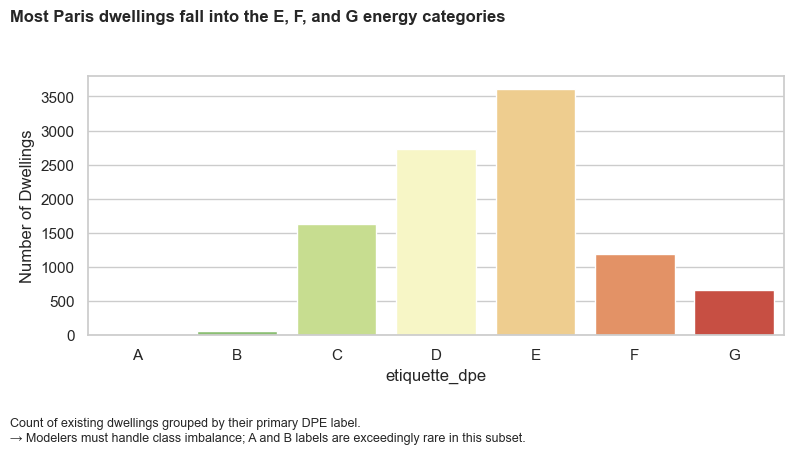

In [22]:
# 5.1 Univariate
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=clean, x="etiquette_dpe", order=["A", "B", "C", "D", "E", "F", "G"], palette="RdYlGn_r", ax=ax)
ax.set_ylabel("Number of Dwellings")
show(fig, "Most Paris dwellings fall into the E, F, and G energy categories", 
     "Count of existing dwellings grouped by their primary DPE label.", 
     "Modelers must handle class imbalance; A and B labels are exceedingly rare in this subset.", "5_1")


### 5.2 Bivariate

C:\Users\CYTech Student\AppData\Local\Temp\ipykernel_24888\2816749685.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean, x="etiquette_dpe", y="surface_habitable_logement", order=["A", "B", "C", "D", "E", "F", "G"], palette="RdYlGn_r", ax=ax)


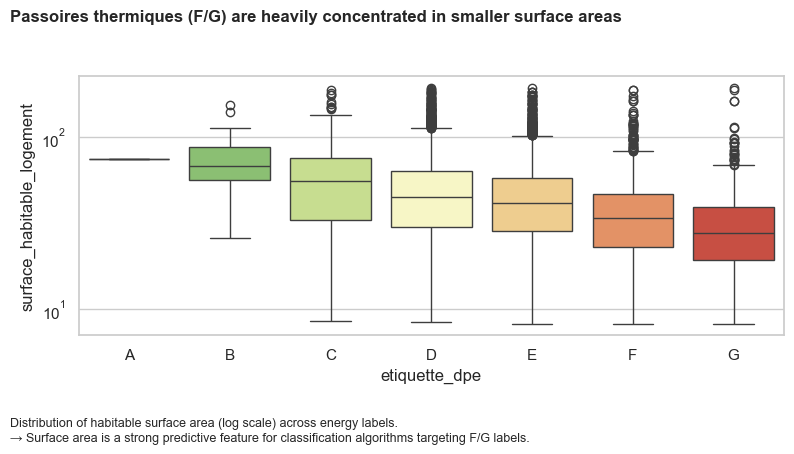

In [23]:

# 5.2 Bivariate
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=clean, x="etiquette_dpe", y="surface_habitable_logement", order=["A", "B", "C", "D", "E", "F", "G"], palette="RdYlGn_r", ax=ax)
ax.set_yscale("log")
show(fig, "Passoires thermiques (F/G) are heavily concentrated in smaller surface areas", 
     "Distribution of habitable surface area (log scale) across energy labels.", 
     "Surface area is a strong predictive feature for classification algorithms targeting F/G labels.", "5_2")

### 5.3 Multivariate

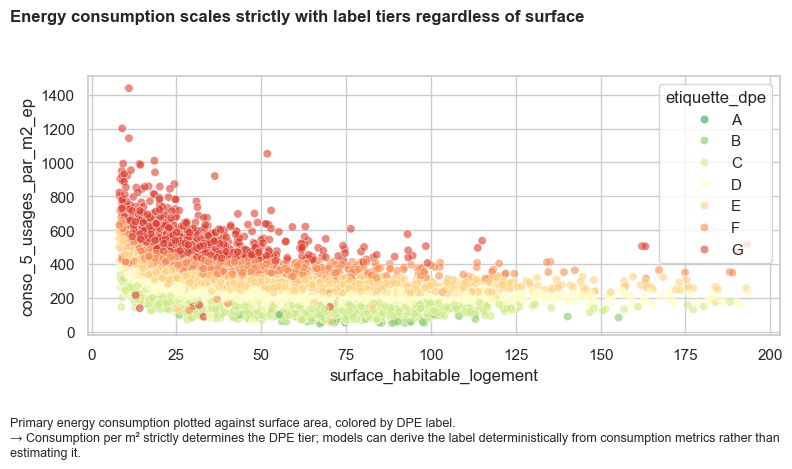

In [24]:

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=clean, x="surface_habitable_logement", y="conso_5_usages_par_m2_ep", hue="etiquette_dpe", hue_order=["A", "B", "C", "D", "E", "F", "G"], palette="RdYlGn_r", alpha=0.6, ax=ax)
show(fig, "Energy consumption scales strictly with label tiers regardless of surface", 
     "Primary energy consumption plotted against surface area, colored by DPE label.", 
     "Consumption per m² strictly determines the DPE tier; models can derive the label deterministically from consumption metrics rather than estimating it.", "5_3")

---
## 6 · Findings, what cannot be trusted, next steps

*TODO*

**Three findings** — each with the figure it comes from and what it means for modelling.
1.
2.
3.

**What cannot be trusted** — column, subset, and why.
-
-

**Five testable hypotheses** — variable, direction, population, test.
- H1:
- H2:
- H3:
- H4:
- H5:

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [ ]:
clean_schema = None                  # TODO: pa.DataFrameSchema({...}, strict=True)
if clean_schema is not None:
    clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.